# Employee PIP Risk Prediction (Classification)

**Problem statement.** A Performance Improvement Plan (PIP) is given to employees whose work has fallen below expectations. Managers often notice struggling employees late. The company wants an **early-warning list** built from data it already has: performance, quality, workload, attendance and conduct.

**Goal.** Build a classification model that predicts `pip_required` (1 = needs a PIP) and use it to:
1. predict which employees are likely to need a PIP,
2. find which factors matter most,
3. turn scores into risk tiers (High / Medium / Watch / Low) that HR can act on, and show how many employees must be reviewed to catch most PIP cases.

**Dataset.** 6,315 employees x 26 columns (6,240 after removing duplicates).

| Column group | Columns |
|---|---|
| Performance | `kpi_score`, `quality_score`, `goal_completion_rate`, `manager_rating` |
| Workload | `tasks_assigned_last_month`, `tasks_completed_last_month`, `overdue_tasks_count`, `rework_count_last_month` |
| Attendance and conduct | `attendance_percentage`, `late_mark_count_30d`, `unplanned_leave_count_3m`, `policy_violation_count_6m`, `client_escalations_count_3m` |
| Profile | `age`, `gender`, `department`, `job_role`, `job_level`, `employment_type`, `tenure_months` |
| Development | `training_hours_last_3m`, `certifications_completed` |
| Admin (dropped) | `employee_id`, `desk_zone`, `laptop_model` |
| Target | `pip_required` |


---
## Part 1: Load the data and take a first look
Import libraries, read the file and check its size and column types.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# ---- 1. Load data (change the path if needed) ----
df = pd.read_csv(r"C:\Users\nazmi\Downloads\PIP_Risk_Dataset.csv")
print("Shape (rows, cols):", df.shape)
display(df.head())

# ---- 2. Data types ----
print("\n--- Data types ---")
print(df.dtypes)

Shape (rows, cols): (6315, 26)


,employee_id,desk_zone,laptop_model,age,gender,department,job_role,job_level,employment_type,tenure_months,attendance_percentage,late_mark_count_30d,unplanned_leave_count_3m,policy_violation_count_6m,kpi_score,goal_completion_rate,tasks_assigned_last_month,tasks_completed_last_month,overdue_tasks_count,quality_score,rework_count_last_month,client_escalations_count_3m,manager_rating,training_hours_last_3m,certifications_completed,pip_required
0,ORG01226,C,HP ProBook,26,Female,Marketing,Content Specialist,2,Full-time,93,93.5,0,2,0,46.5,0.632,36,27,3,67.4,4,0,3.0,32.1,3,0
1,ORG03879,A,Lenovo ThinkPad,31,Male,Engineering,Software Engineer,2,Full-time,67,94.4,2,0,0,59.3,0.753,42,31,4,70.0,2,1,4.0,23.2,2,0
2,ORG04879,D,Dell Latitude,29,Female,Sales,Inside Sales Rep,2,Full-time,82,96.5,0,0,0,48.8,0.302,48,33,3,38.3,3,4,1.0,12.9,0,0
3,ORG05202,A,Lenovo ThinkPad,29,Male,Engineering,Data Analyst,4,Contract,2,90.0,3,0,2,67.2,0.857,66,47,14,79.9,3,0,3.0,28.0,4,0
4,ORG01484,D,Lenovo ThinkPad,29,Female,Sales,Inside Sales Rep,3,Contract,7,98.9,1,0,0,81.5,0.740,51,42,4,71.7,2,0,3.0,13.3,4,0



--- Data types ---
employee_id                     object
desk_zone                       object
laptop_model                    object
age                              int64
gender                          object
department                      object
job_role                        object
job_level                        int64
employment_type                 object
tenure_months                    int64
attendance_percentage          float64
late_mark_count_30d              int64
unplanned_leave_count_3m         int64
policy_violation_count_6m        int64
kpi_score                      float64
goal_completion_rate           float64
tasks_assigned_last_month        int64
tasks_completed_last_month       int64
overdue_tasks_count              int64
quality_score                  float64
rework_count_last_month          int64
client_escalations_count_3m      int64
manager_rating                 float64
training_hours_last_3m         float64
certifications_completed         int64
pip_r

**Inference (structure)**
- 6,315 employees and 26 columns: performance, workload, attendance and conduct numbers, employee profile columns, and 3 admin columns (`employee_id`, `desk_zone`, `laptop_model`).
- The target `pip_required` is 0/1. Everything else is either a number or a text category (gender, department, job role, employment type).

---
## Part 2: Data quality checks
Before modelling we look for blanks, duplicates, impossible values and class imbalance.

In [3]:
# ---- 3. Missing values ----
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)
print("\n--- Columns with missing values ---")
print(missing if len(missing) else "No missing values found")

# ---- 4. Duplicates ----
print("\n--- Duplicates ---")
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated employee_id:", df["employee_id"].duplicated().sum())


--- Columns with missing values ---
                        missing_count  missing_pct
attendance_percentage              46         0.73
kpi_score                          46         0.73
manager_rating                     45         0.71
training_hours_last_3m             43         0.68
goal_completion_rate               41         0.65
quality_score                      36         0.57

--- Duplicates ---
Fully duplicated rows: 75
Duplicated employee_id: 75


**Inference (missing values and duplicates)**
- Six columns have a few blanks: attendance (46), KPI (46), manager rating (45), training hours (43), goal completion (41) and quality score (36). Each is **under 0.8%**, so we fill them later inside the pipeline instead of deleting rows.
- **75 rows are exact duplicates** (same `employee_id` repeated). They must be removed, otherwise one employee could sit in both train and test and make the results look better than they are.


--- Target: pip_required ---
pip_required
0    5043
1    1272
Name: count, dtype: int64
pip_required
0    79.86
1    20.14
Name: proportion, dtype: float64


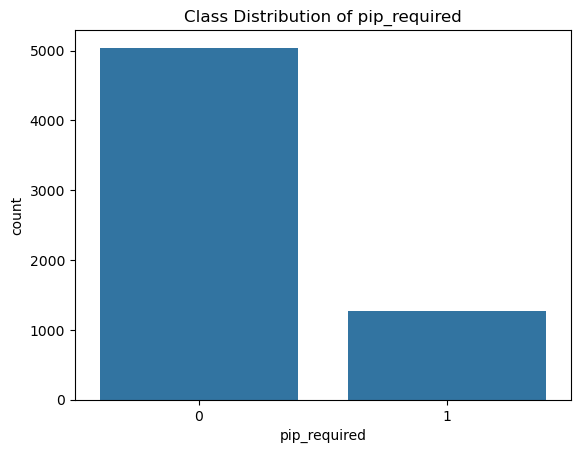


--- Numeric summary ---


,count,mean,std,min,25%,50%,75%,max
age,6315.0,29.003800,4.449091,21.0,26.000,29.000,32.000,46.0
job_level,6315.0,2.572288,1.041410,1.0,2.000,3.000,3.000,5.0
tenure_months,6315.0,54.148852,36.031592,1.0,19.000,52.000,86.000,120.0
attendance_percentage,6269.0,94.828617,3.385836,83.6,92.500,94.900,97.500,100.0
late_mark_count_30d,6315.0,1.424545,1.400642,0.0,0.000,1.000,2.000,10.0
unplanned_leave_count_3m,6315.0,1.415994,1.357774,0.0,0.000,1.000,2.000,10.0
policy_violation_count_6m,6315.0,0.404276,0.705300,0.0,0.000,0.000,1.000,7.0
kpi_score,6269.0,67.188068,14.515185,25.0,57.600,67.200,77.000,98.0
goal_completion_rate,6274.0,0.699658,0.155063,0.1,0.598,0.703,0.806,1.0
tasks_assigned_last_month,6315.0,60.569596,27.704394,14.0,41.000,55.000,74.000,151.0



--- Sanity check violations ---
attendance_percentage outside 0-100: 0
goal_completion_rate < 0: 0
tasks_completed > tasks_assigned: 0
overdue_tasks_count > tasks_assigned: 0
tasks_assigned == 0 (future divide-by-zero): 0
negative values in count columns: 0

--- Categorical cardinality ---
gender: 3 unique -> ['Female' 'Male' 'Other']
department: 8 unique -> ['Marketing' 'Engineering' 'Sales' 'Customer Support' 'Operations'
 'Finance' 'IT' 'HR']
job_role: 22 unique -> ['Content Specialist' 'Software Engineer' 'Inside Sales Rep'
 'Data Analyst' 'Support Associate' 'DevOps Engineer' 'Sales Executive'
 'Marketing Executive']
employment_type: 2 unique -> ['Full-time' 'Contract']

Shape after dropping admin columns: (6315, 23)


In [4]:
# ---- 5. Target distribution (class imbalance check) ----
print("\n--- Target: pip_required ---")
print(df["pip_required"].value_counts(dropna=False))
print((df["pip_required"].value_counts(normalize=True) * 100).round(2))
sns.countplot(x="pip_required", data=df)
plt.title("Class Distribution of pip_required")
plt.show()

# ---- 6. Column sanity checks ----
print("\n--- Numeric summary ---")
display(df.describe().T)

checks = {
    "attendance_percentage outside 0-100": ~df["attendance_percentage"].dropna().between(0, 100),
    "goal_completion_rate < 0": df["goal_completion_rate"].dropna() < 0,
    "tasks_completed > tasks_assigned": df["tasks_completed_last_month"] > df["tasks_assigned_last_month"],
    "overdue_tasks_count > tasks_assigned": df["overdue_tasks_count"] > df["tasks_assigned_last_month"],
    "tasks_assigned == 0 (future divide-by-zero)": df["tasks_assigned_last_month"] == 0,
    "negative values in count columns": (df[[
        "late_mark_count_30d", "unplanned_leave_count_3m", "policy_violation_count_6m",
        "overdue_tasks_count", "rework_count_last_month", "client_escalations_count_3m",
        "certifications_completed"]] < 0).any(axis=1),
}
print("\n--- Sanity check violations ---")
for name, mask in checks.items():
    print(f"{name}: {int(mask.sum())}")

# ---- 7. Categorical overview ----
cat_cols = ["gender", "department", "job_role", "employment_type"]
print("\n--- Categorical cardinality ---")
for c in cat_cols:
    print(f"{c}: {df[c].nunique()} unique -> {df[c].unique()[:8]}")

# ---- 8. Drop administrative/noise columns (on a copy) ----
admin_cols = ["employee_id", "desk_zone", "laptop_model"]
df_clean = df.drop(columns=admin_cols).copy()
print("\nShape after dropping admin columns:", df_clean.shape)

**Inference (target balance and sanity checks)**
- **Target:** 79.86% no PIP and 20.14% PIP (1,272 of 6,315). The classes are imbalanced about 4 to 1.
- All six sanity checks show **0 violations**: attendance is within 0-100, no negative counts, tasks completed never exceed tasks assigned, nobody has zero tasks assigned. The data is clean, so ratio features are safe to build later.
- A typical employee has KPI 67, quality 69.7, attendance 94.8% and manager rating 3.4 out of 5. There are 8 departments, 22 job roles and 2 employment types (Full-time, Contract).


---
## Part 3: Clean the data
Remove the duplicate employees and the admin columns that have no link to performance.

In [5]:
# ---- Step 1 patch: remove exact duplicates from the RAW data ----
print("Before:", df.shape)

# Confirm the duplicates are true copies of the same employee
dup_mask = df.duplicated(keep=False)
print("Rows involved in duplication (originals + copies):", dup_mask.sum())

df = df.drop_duplicates(keep="first").reset_index(drop=True)

print("After :", df.shape)
print("Remaining fully duplicated rows:", df.duplicated().sum())
print("Remaining duplicated employee_id:", df["employee_id"].duplicated().sum())

# Rebuild df_clean from the de-duplicated data (drop admin columns AFTER dedup)
admin_cols = ["employee_id", "desk_zone", "laptop_model"]
df_clean = df.drop(columns=admin_cols).copy()
print("df_clean shape:", df_clean.shape)

# Re-check the target balance after dedup
print((df_clean["pip_required"].value_counts(normalize=True) * 100).round(2))

Before: (6315, 26)
Rows involved in duplication (originals + copies): 150
After : (6240, 26)
Remaining fully duplicated rows: 0
Remaining duplicated employee_id: 0
df_clean shape: (6240, 23)
pip_required
0    79.89
1    20.11
Name: proportion, dtype: float64


**Inference (cleaning)**
- 75 duplicate rows were removed: **6,315 -> 6,240 rows**. No duplicate rows or ids remain.
- The PIP rate barely changed (20.14% -> 20.11%), so removing duplicates did not distort the target.
- The 3 admin columns were dropped *after* de-duplication. The clean table `df_clean` has 23 columns.

## Part 4: Exploratory data analysis (EDA)
We compare employees who need a PIP with those who do not, to see which signals separate them.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
target = "pip_required"

num_cols = df_clean.select_dtypes(include=np.number).columns.drop(target).tolist()
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()

print("Shape:", df_clean.shape)
print("Numeric features:", len(num_cols))
print("Categorical features:", cat_cols)

Shape: (6240, 23)
Numeric features: 18
Categorical features: ['gender', 'department', 'job_role', 'employment_type']


**Inference (column types)**
- 18 numeric features and 4 text features (`gender`, `department`, `job_role`, `employment_type`). The target is kept separate.

In [7]:
group_means = df_clean.groupby(target)[num_cols].mean().T
group_means.columns = ["No_PIP_mean", "PIP_mean"]
group_means["diff_%"] = ((group_means["PIP_mean"] - group_means["No_PIP_mean"])
                         / group_means["No_PIP_mean"] * 100).round(1)
display(group_means.sort_values("diff_%", key=abs, ascending=False).round(3))

,No_PIP_mean,PIP_mean,diff_%
client_escalations_count_3m,0.621,1.245,100.4
rework_count_last_month,1.492,2.423,62.4
policy_violation_count_6m,0.367,0.559,52.3
unplanned_leave_count_3m,1.307,1.853,41.8
overdue_tasks_count,5.583,7.834,40.3
late_mark_count_30d,1.332,1.796,34.8
manager_rating,3.616,2.526,-30.2
kpi_score,70.378,54.559,-22.5
goal_completion_rate,0.731,0.577,-21.0
quality_score,72.417,58.882,-18.7


**Inference (average values by class)**
- Employees with a PIP have **more** client escalations (+100%: 0.62 -> 1.25), rework (+62%), policy violations (+52%), unplanned leave (+42%) and overdue tasks (+40%).
- They have **lower** manager rating (-30%), KPI (-22.5%), goal completion (-21%) and quality score (-19%).
- Age, tenure, certifications and tasks completed hardly differ (under 10%).

> **In simple words:** PIP employees make more mistakes and cause more escalations, and score lower on KPI, quality and manager rating.

quality_score                 -0.439
kpi_score                     -0.437
manager_rating                -0.428
goal_completion_rate          -0.396
attendance_percentage         -0.200
job_level                     -0.098
age                           -0.085
tenure_months                 -0.056
training_hours_last_3m        -0.046
tasks_completed_last_month    -0.020
certifications_completed      -0.017
tasks_assigned_last_month      0.087
policy_violation_count_6m      0.109
late_mark_count_30d            0.133
unplanned_leave_count_3m       0.161
overdue_tasks_count            0.194
client_escalations_count_3m    0.249
rework_count_last_month        0.256
Name: pip_required, dtype: float64


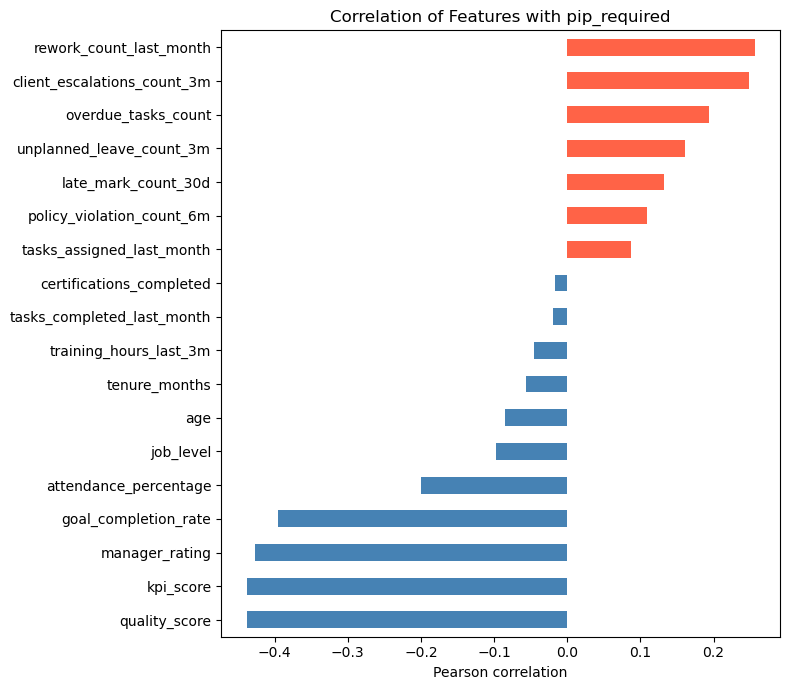

In [8]:
corr_target = df_clean[num_cols + [target]].corr()[target].drop(target).sort_values()
print(corr_target.round(3))

plt.figure(figsize=(8, 7))
corr_target.plot(kind="barh", color=np.where(corr_target > 0, "tomato", "steelblue"))
plt.title("Correlation of Features with pip_required")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

**Inference (correlation with the target)**
- Strongest **negative** links: quality score (-0.44), KPI (-0.44), manager rating (-0.43), goal completion (-0.40).
- Strongest **positive** links: rework (+0.26), client escalations (+0.25), overdue tasks (+0.19).
- No single feature goes beyond about 0.45, so the PIP decision depends on **several signals together**, not one metric.

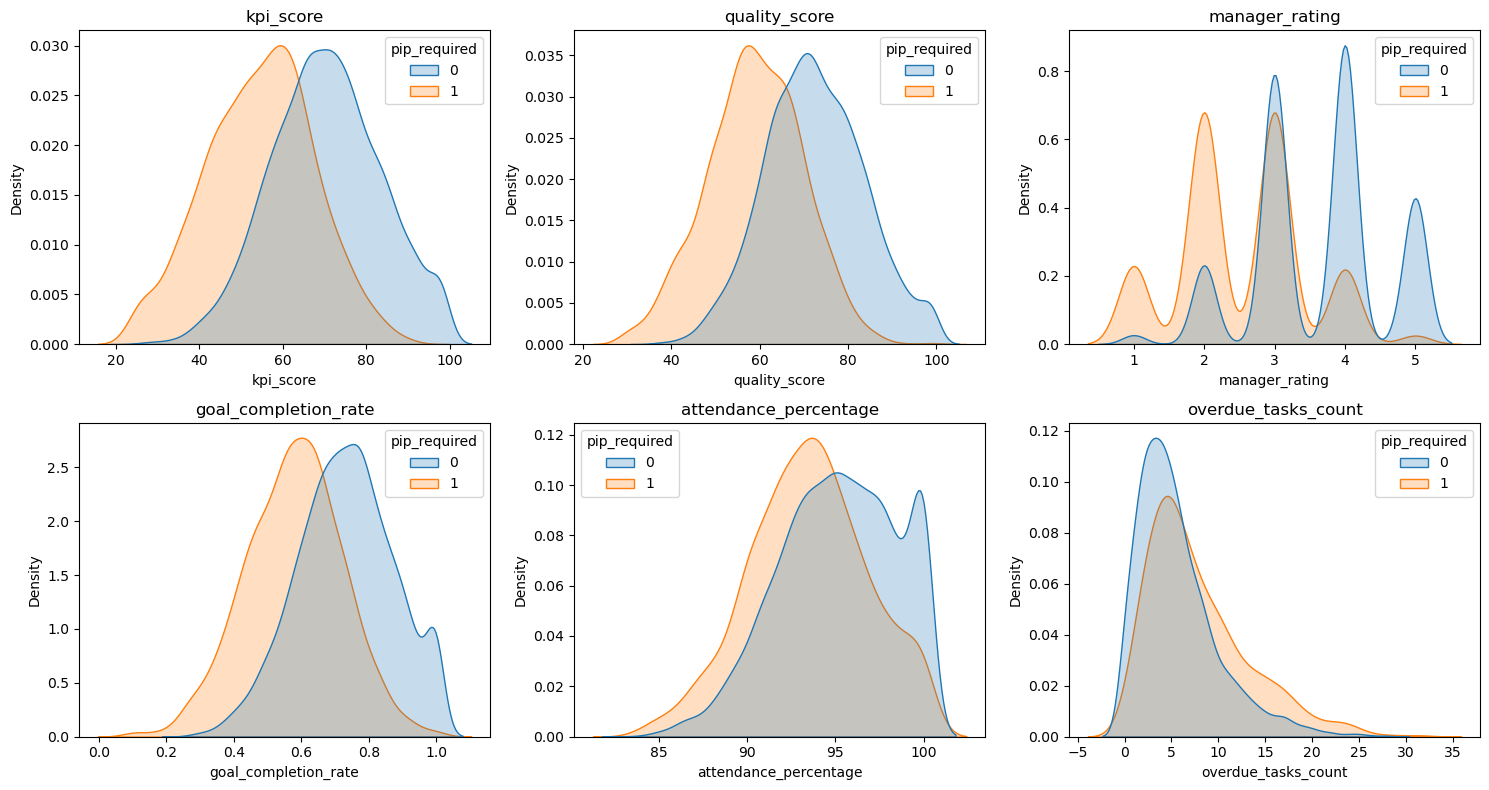

In [9]:
key_feats = ["kpi_score", "quality_score", "manager_rating",
             "goal_completion_rate", "attendance_percentage", "overdue_tasks_count"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_feats):
    sns.kdeplot(data=df_clean, x=col, hue=target, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Inference (distribution plots)**
- For KPI, quality, manager rating, goal completion and attendance the PIP curves sit toward **lower** values, and for overdue tasks toward **higher** values. This matches the averages above.
- The curves **overlap a lot**, so no single feature can separate the two groups. We need a model that combines them.

--- Feature pairs with |correlation| > 0.6 ---
tasks_assigned_last_month   tasks_completed_last_month    0.964
                            overdue_tasks_count           0.762
kpi_score                   quality_score                 0.691
age                         job_level                     0.675
goal_completion_rate        manager_rating                0.669
tasks_completed_last_month  overdue_tasks_count           0.650
kpi_score                   goal_completion_rate          0.643
goal_completion_rate        quality_score                 0.640
kpi_score                   manager_rating                0.609
dtype: float64


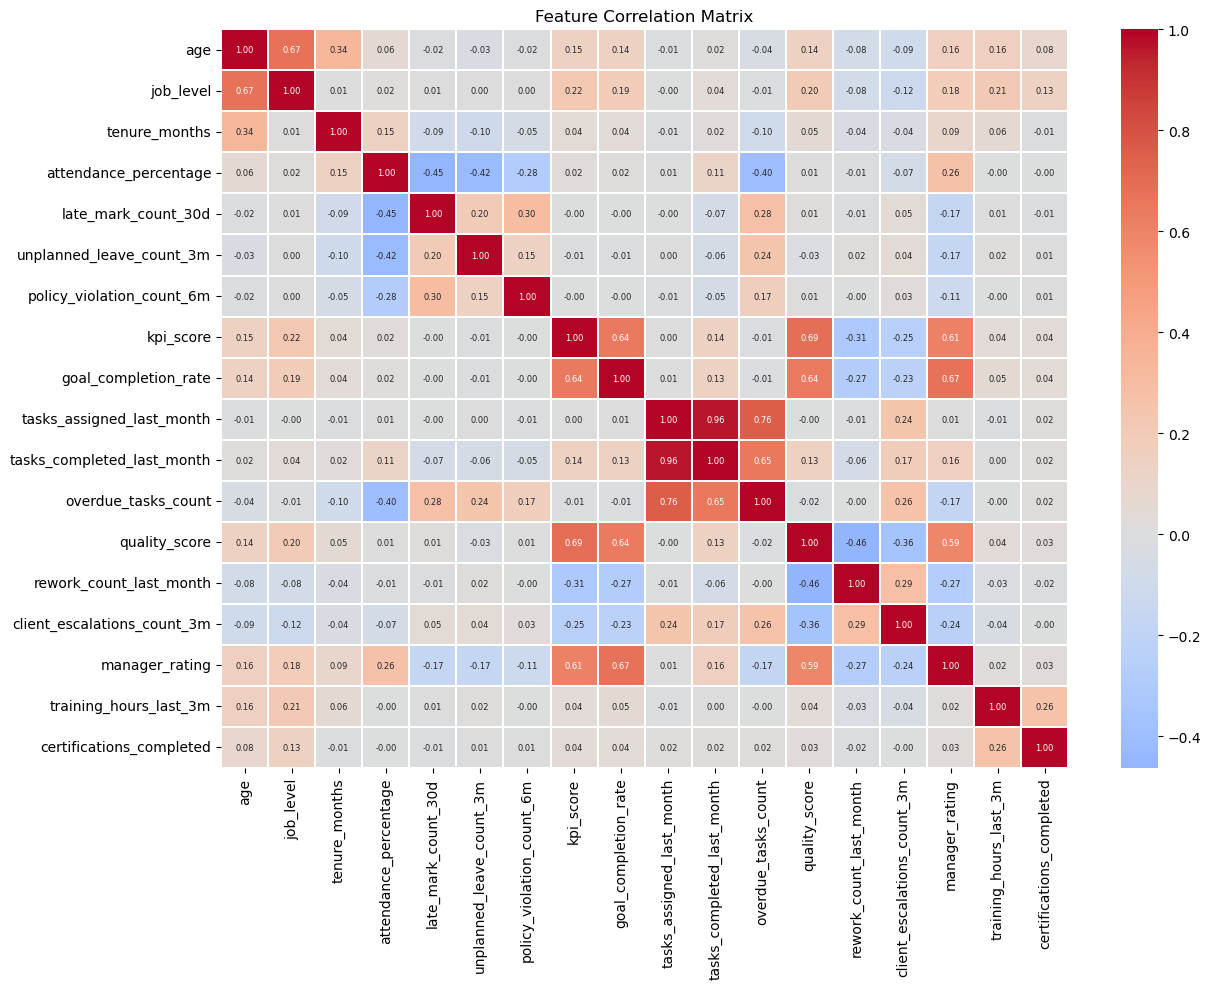

In [10]:
corr = df_clean[num_cols].corr()
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("--- Feature pairs with |correlation| > 0.6 ---")
print(pairs[pairs > 0.6].round(3))

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6}, linewidths=0.3)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**Inference (correlation between features)**
- Nine pairs correlate above 0.6. The strongest are tasks assigned and tasks completed (0.96), tasks assigned and overdue (0.76), KPI and quality (0.69), age and job level (0.68), goal completion and manager rating (0.67).
- Features that move together carry **overlapping information** and make logistic regression coefficients unstable, so the task columns are replaced by ratios in Part 5.

In [11]:
for c in ["department", "employment_type", "gender", "job_level"]:
    rate = (df_clean.groupby(c)[target].agg(["mean", "count"])
            .rename(columns={"mean": "pip_rate"})
            .sort_values("pip_rate", ascending=False))
    print(f"\n--- PIP rate by {c} ---")
    display(rate.round(3))


--- PIP rate by department ---


,pip_rate,count
department,,
Customer Support,0.256,1019
Operations,0.237,864
Sales,0.213,1118
Finance,0.194,598
HR,0.194,377
IT,0.179,346
Marketing,0.174,493
Engineering,0.150,1425



--- PIP rate by employment_type ---


,pip_rate,count
employment_type,,
Contract,0.238,797
Full-time,0.196,5443



--- PIP rate by gender ---


,pip_rate,count
gender,,
Male,0.204,3568
Female,0.198,2615
Other,0.193,57



--- PIP rate by job_level ---


,pip_rate,count
job_level,,
1,0.256,1008
2,0.227,2079
3,0.185,1939
4,0.140,1018
5,0.128,196


**Inference (PIP rate by group)**
- **Department:** Customer Support (25.6%), Operations (23.7%) and Sales (21.3%) are highest; Engineering is lowest (15.0%).
- **Employment type:** Contract 23.8% against Full-time 19.6%.
- **Job level:** the rate falls steadily from level 1 (25.6%) to level 5 (12.8%): junior employees are more often placed on a PIP.
- **Gender:** Male 20.4%, Female 19.8%, Other 19.3%. There is no meaningful difference, and gender should not drive HR decisions, so **gender is not used in the model**.

## Part 5: Feature engineering
Raw counts depend on workload. Ratios let us compare a busy employee and a quiet one fairly.

In [12]:
df_fe = df_clean.copy()

# ---- 1. Task completion rate: how much of the workload gets finished ----
df_fe["task_completion_rate"] = (
    df_fe["tasks_completed_last_month"] / df_fe["tasks_assigned_last_month"]
)

# ---- 2. Overdue ratio: share of assigned work that is late (workload-adjusted) ----
df_fe["overdue_task_ratio"] = (
    df_fe["overdue_tasks_count"] / df_fe["tasks_assigned_last_month"]
)

# ---- 3. Rework ratio: share of completed work that needed fixing ----
# +1 in the denominator avoids dividing by zero if someone completed 0 tasks
df_fe["rework_ratio"] = (
    df_fe["rework_count_last_month"] / (df_fe["tasks_completed_last_month"] + 1)
)

In [13]:
# ---- 4. Attendance risk index: combines 3 attendance-related warning signs ----
# Domain-weighted, row-wise formula (no learned parameters, so no leakage)
df_fe["attendance_risk_index"] = (
    (100 - df_fe["attendance_percentage"])        # absence level (NaN stays NaN)
    + 2 * df_fe["late_mark_count_30d"]            # lateness
    + 2 * df_fe["unplanned_leave_count_3m"]       # surprise absences
)

In [14]:
# ---- 5. Sanity checks on the new features ----
new_feats = ["task_completion_rate", "overdue_task_ratio",
             "rework_ratio", "attendance_risk_index"]
print("--- Summary of engineered features ---")
display(df_fe[new_feats].describe().T.round(3))

print("\n--- Inf / NaN check ---")
print("Inf values:", np.isinf(df_fe[new_feats]).sum().sum())
print(df_fe[new_feats].isna().sum())

# ---- 6. Do the new features carry signal? ----
print("\n--- Correlation with target (new vs old) ---")
cmp_cols = new_feats + ["tasks_assigned_last_month", "tasks_completed_last_month",
                        "overdue_tasks_count", "rework_count_last_month",
                        "attendance_percentage"]
print(df_fe[cmp_cols + [target]].corr()[target].drop(target).sort_values().round(3))

print("\n--- Means by class ---")
display(df_fe.groupby(target)[new_feats].mean().T.round(3))

# ---- 7. Did we reduce multicollinearity? ----
print("\n--- Correlations among task-related features ---")
display(df_fe[["tasks_assigned_last_month", "tasks_completed_last_month",
               "overdue_tasks_count", "task_completion_rate",
               "overdue_task_ratio"]].corr().round(3))

--- Summary of engineered features ---


,count,mean,std,min,25%,50%,75%,max
task_completion_rate,6240.0,0.796,0.092,0.451,0.734,0.799,0.861,0.980
overdue_task_ratio,6240.0,0.094,0.047,0.000,0.062,0.094,0.125,0.261
rework_ratio,6240.0,0.044,0.050,0.000,0.011,0.030,0.059,0.615
attendance_risk_index,6194.0,10.859,6.794,0.000,5.700,10.400,15.300,40.500



--- Inf / NaN check ---
Inf values: 0
task_completion_rate      0
overdue_task_ratio        0
rework_ratio              0
attendance_risk_index    46
dtype: int64

--- Correlation with target (new vs old) ---
task_completion_rate         -0.408
attendance_percentage        -0.200
tasks_completed_last_month   -0.020
tasks_assigned_last_month     0.087
overdue_tasks_count           0.194
overdue_task_ratio            0.210
rework_ratio                  0.217
attendance_risk_index         0.219
rework_count_last_month       0.256
Name: pip_required, dtype: float64

--- Means by class ---


pip_required,0,1
task_completion_rate,0.815,0.721
overdue_task_ratio,0.089,0.114
rework_ratio,0.038,0.065
attendance_risk_index,10.113,13.815



--- Correlations among task-related features ---


,tasks_assigned_last_month,tasks_completed_last_month,overdue_tasks_count,task_completion_rate,overdue_task_ratio
tasks_assigned_last_month,1.000,0.964,0.762,0.054,0.262
tasks_completed_last_month,0.964,1.000,0.650,0.292,0.138
overdue_tasks_count,0.762,0.650,1.000,-0.249,0.763
task_completion_rate,0.054,0.292,-0.249,1.000,-0.449
overdue_task_ratio,0.262,0.138,0.763,-0.449,1.000


**Inference (new features)**
- Four features were created: `task_completion_rate` (completed / assigned), `overdue_task_ratio` (overdue / assigned), `rework_ratio` (rework / completed) and `attendance_risk_index` (absence % + 2 x late marks + 2 x unplanned leaves). There are no infinite values; only `attendance_risk_index` has 46 blanks, inherited from attendance.
- `task_completion_rate` has a correlation of **-0.41** with PIP, far stronger than the raw counts it replaces (completed -0.02, assigned +0.09). `attendance_risk_index` (0.22) also beats attendance % alone (-0.20).
- The overlap between features dropped: tasks assigned and completed were 0.96 correlated, but completion rate has only 0.05 correlation with tasks assigned.
- PIP employees complete **72%** of assigned work against 82% for others (0.721 vs 0.815), and have attendance risk 13.8 against 10.1.

> **In simple words:** instead of asking "how many tasks?", we ask "what share of the work got done and what share was late?"

## Part 6: Train/test split and preprocessing
We keep 20% of employees aside as a final exam. All learning (medians, scaling, categories) uses **training data only**.

In [15]:
from sklearn.model_selection import train_test_split

# ---- 1. Drop the columns we decided to remove ----
drop_cols = ["gender",
             "tasks_completed_last_month",   # replaced by task_completion_rate
             "overdue_tasks_count",          # replaced by overdue_task_ratio
             "attendance_percentage",        # folded into attendance_risk_index
             "late_mark_count_30d",          # folded into attendance_risk_index
             "unplanned_leave_count_3m"]     # folded into attendance_risk_index

df_model = df_fe.drop(columns=drop_cols).copy()

# ---- 2. Separate features (X) and target (y) ----
X = df_model.drop(columns=[target])
y = df_model[target]

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()
print("Numeric features  :", len(num_features), num_features)
print("Categorical       :", len(cat_features), cat_features)

# ---- 3. Stratified 80/20 split ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# ---- 4. Verify the split ----
print("\nX_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nPIP rate  -> full: {:.4f} | train: {:.4f} | test: {:.4f}".format(
    y.mean(), y_train.mean(), y_test.mean()))
print("\nTrain class counts:\n", y_train.value_counts())
print("\nTest class counts:\n", y_test.value_counts())

# ---- 5. Missing values now live in TRAIN and TEST separately ----
print("\nMissing in train:\n", X_train.isna().sum()[X_train.isna().sum() > 0])
print("\nMissing in test:\n", X_test.isna().sum()[X_test.isna().sum() > 0])

# ---- 6. Check the collinearity of the two rework features ----
print("\nCorr(rework_count, rework_ratio) on TRAIN:",
      round(X_train["rework_count_last_month"].corr(X_train["rework_ratio"]), 3))

Numeric features  : 17 ['age', 'job_level', 'tenure_months', 'policy_violation_count_6m', 'kpi_score', 'goal_completion_rate', 'tasks_assigned_last_month', 'quality_score', 'rework_count_last_month', 'client_escalations_count_3m', 'manager_rating', 'training_hours_last_3m', 'certifications_completed', 'task_completion_rate', 'overdue_task_ratio', 'rework_ratio', 'attendance_risk_index']
Categorical       : 3 ['department', 'job_role', 'employment_type']

X_train: (4992, 20) | X_test: (1248, 20)

PIP rate  -> full: 0.2011 | train: 0.2011 | test: 0.2011

Train class counts:
 pip_required
0    3988
1    1004
Name: count, dtype: int64

Test class counts:
 pip_required
0    997
1    251
Name: count, dtype: int64

Missing in train:
 kpi_score                 36
goal_completion_rate      31
quality_score             27
manager_rating            32
training_hours_last_3m    37
attendance_risk_index     35
dtype: int64

Missing in test:
 kpi_score                  9
goal_completion_rate       9

**Inference (split)**
- Dropped: `gender` (fairness) and five raw columns that are now covered by ratios or the attendance index.
- Stratified 80/20 split: **4,992 train / 1,248 test**, with the PIP rate at 20.11% in the full data, train and test, so both parts look alike.
- Blanks are few (27-37 per column in train, 6-13 in test). On the training data `rework_ratio` is 0.805 correlated with `rework_count_last_month`, so it is dropped in the next step.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ---- 1. Drop rework_ratio (0.805 correlated with rework_count) ----
X_train = X_train.drop(columns=["rework_ratio"])
X_test  = X_test.drop(columns=["rework_ratio"])

num_features = X_train.select_dtypes(include=np.number).columns.tolist()
cat_features = X_train.select_dtypes(include="object").columns.tolist()
print("Numeric:", len(num_features), "| Categorical:", len(cat_features))

# ---- 2. Numeric branch: impute with median, then standardize ----
numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ---- 3. Categorical branch: impute mode, then one-hot encode ----
categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                             sparse_output=False))
])

# ---- 4. Combine both branches ----
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features)
])

# ---- 5. Fit on TRAIN only, then transform both ----
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("\nProcessed train:", X_train_proc.shape, "| test:", X_test_proc.shape)
print("NaNs after processing -> train:", np.isnan(X_train_proc).sum(),
      "| test:", np.isnan(X_test_proc).sum())

Numeric: 16 | Categorical: 3

Processed train: (4992, 47) | test: (1248, 47)
NaNs after processing -> train: 0 | test: 0


**Inference (preprocessing)**
- Numeric columns: fill blanks with the median, then standardise (mean 0, standard deviation 1). Text columns: fill with the most frequent value, then one-hot encode.
- 16 numeric + 3 text features (`department`, `job_role`, `employment_type`) become **47 columns with no missing values**.

## Part 7: Baseline model
A plain logistic regression sets the bar. A "lazy" model that always predicts "no PIP" shows what doing nothing scores.

In [17]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)

# ---- 1. Full pipeline = preprocessing + model (so CV refits prep inside each fold) ----
baseline = Pipeline(steps=[
    ("prep", clone(preprocessor)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
baseline.fit(X_train, y_train)

# ---- 2. Lazy reference: always predicts the majority class ----
dummy = Pipeline(steps=[
    ("prep", clone(preprocessor)),
    ("clf", DummyClassifier(strategy="prior"))
])
dummy.fit(X_train, y_train)

# ---- 3. Evaluation helper ----
def evaluate(model, X, y, name, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
    }

results = pd.DataFrame([
    evaluate(dummy,    X_test,  y_test,  "Dummy (TEST)"),
    evaluate(baseline, X_train, y_train, "LogReg (TRAIN)"),
    evaluate(baseline, X_test,  y_test,  "LogReg (TEST)"),
]).set_index("model").round(3)
print("--- Baseline results (threshold = 0.5) ---")
display(results)

# ---- 4. Confusion matrix and report on TEST ----
proba_test = baseline.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred_test)
print("\n--- Confusion matrix (rows = actual, cols = predicted) ---")
print(pd.DataFrame(cm, index=["Actual No PIP", "Actual PIP"],
                   columns=["Pred No PIP", "Pred PIP"]))
print("\n--- Classification report (TEST) ---")
print(classification_report(y_test, pred_test, target_names=["No PIP", "PIP"], digits=3))

# ---- 5. 5-fold stratified CV on TRAIN: is the test score stable? ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(
    baseline, X_train, y_train, cv=cv,
    scoring=["roc_auc", "average_precision", "recall", "precision", "f1"]
)
cv_df = pd.DataFrame({k.replace("test_", ""): v for k, v in cv_res.items()
                      if k.startswith("test_")})
print("\n--- 5-fold CV on TRAIN (mean / std) ---")
print(cv_df.agg(["mean", "std"]).T.round(3))


--- Baseline results (threshold = 0.5) ---


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Dummy (TEST),0.799,0.000,0.000,0.000,0.500,0.201
LogReg (TRAIN),0.856,0.706,0.487,0.576,0.882,0.691
LogReg (TEST),0.860,0.741,0.466,0.572,0.880,0.696



--- Confusion matrix (rows = actual, cols = predicted) ---
               Pred No PIP  Pred PIP
Actual No PIP          956        41
Actual PIP             134       117

--- Classification report (TEST) ---
              precision    recall  f1-score   support

      No PIP      0.877     0.959     0.916       997
         PIP      0.741     0.466     0.572       251

    accuracy                          0.860      1248
   macro avg      0.809     0.713     0.744      1248
weighted avg      0.850     0.860     0.847      1248


--- 5-fold CV on TRAIN (mean / std) ---
                    mean    std
roc_auc            0.876  0.018
average_precision  0.680  0.033
recall             0.477  0.045
precision          0.690  0.040
f1                 0.563  0.034


**Inference (baseline performance)**
- Accuracy is 86.0%, but the lazy model already scores **79.9%** (with recall 0), so the real gain is small.
- At the default 0.5 cut-off the model finds only **46.6% of PIP cases** (117 of 251) and misses 134. When it says PIP it is right 74.1% of the time.
- **ROC-AUC is 0.880** on test and 0.876 in 5-fold cross-validation: employees are ranked well and the result is stable. PR-AUC is 0.696 against a 0.201 chance level.
- Train and test scores are almost the same (AUC 0.882 and 0.880), so there is **no overfitting**.

> **In simple words:** the model ranks employees well, but the 0.5 cut-off is too strict and lets more than half of the PIP cases slip through.

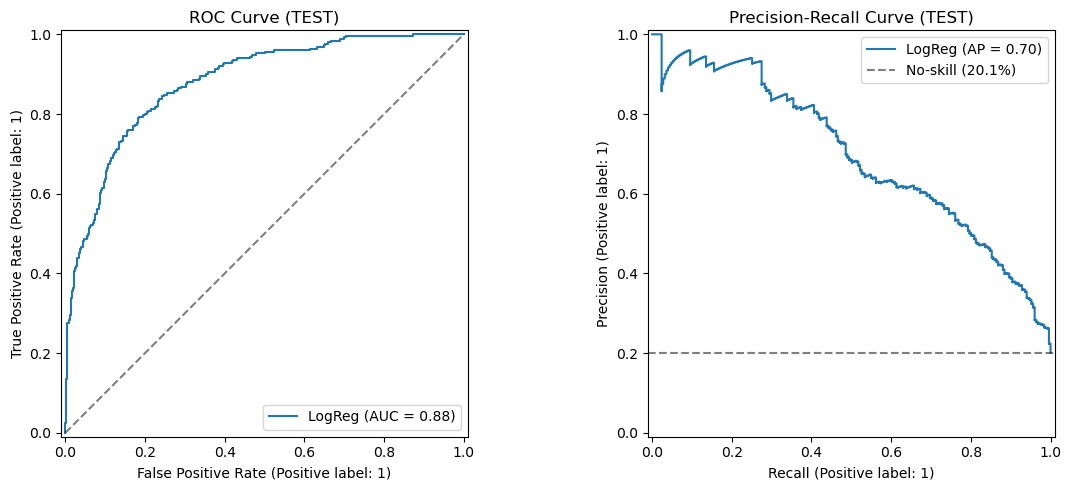

In [18]:
# ---- 6. ROC and Precision-Recall curves on TEST ----
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax[0], name="LogReg")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[0].set_title("ROC Curve (TEST)")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax[1], name="LogReg")
ax[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.5, label="No-skill (20.1%)")
ax[1].legend()
ax[1].set_title("Precision-Recall Curve (TEST)")
plt.tight_layout()
plt.show()

**Inference (ROC and precision-recall curves)**
- The ROC curve sits well above the diagonal (AUC 0.88). The precision-recall curve stays well above the no-skill line (20.1%).
- Precision falls as recall rises. This trade-off is what the cut-off controls in the next part.

---
## Part 8: Fix the class imbalance and choose a cut-off
Class weights tell the model that missing a PIP case costs more. The cut-off is chosen on **out-of-fold training scores**, so the test set stays untouched.

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score

# ---- 1. Class-weighted logistic regression (same preprocessing) ----
weighted = Pipeline(steps=[
    ("prep", clone(preprocessor)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=42))
])

# ---- 2. Out-of-fold probabilities on TRAIN (test set stays untouched) ----
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_base = cross_val_predict(baseline, X_train, y_train, cv=skf,
                             method="predict_proba")[:, 1]
oof_w = cross_val_predict(weighted, X_train, y_train, cv=skf,
                          method="predict_proba")[:, 1]
print("OOF ROC-AUC  baseline: {:.3f} | weighted: {:.3f}".format(
    roc_auc_score(y_train, oof_base), roc_auc_score(y_train, oof_w)))

# ---- 3. Precision / recall at different cutoffs (weighted model) ----
rows = []
for t in np.arange(0.20, 0.81, 0.05):
    pred = (oof_w >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "flagged_%": pred.mean() * 100,
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred),
        "f2": fbeta_score(y_train, pred, beta=2),
    })
thr_table = pd.DataFrame(rows).set_index("threshold").round(3)
display(thr_table)

# ---- 4. Pick the cutoff with the best F2 (recall counts double) ----
best_t = thr_table["f2"].idxmax()
print("\nBest threshold by F2 (from train OOF):", best_t)

# ---- 5. One look at TEST using that cutoff ----
weighted.fit(X_train, y_train)
proba_test_w = weighted.predict_proba(X_test)[:, 1]
pred_test = (proba_test_w >= best_t).astype(int)
print("\nTEST @ threshold", best_t)
print(confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test,
                            target_names=["No PIP", "PIP"], digits=3))

OOF ROC-AUC  baseline: 0.876 | weighted: 0.876


,flagged_%,precision,recall,f1,f2
threshold,,,,,
0.20,58.313,0.327,0.949,0.487,0.688
0.25,52.183,0.357,0.927,0.516,0.703
0.30,47.476,0.385,0.908,0.541,0.714
0.35,43.790,0.407,0.886,0.558,0.718
0.40,39.944,0.435,0.864,0.578,0.721
0.45,36.659,0.458,0.836,0.592,0.718
0.50,33.253,0.487,0.805,0.607,0.712
0.55,30.168,0.510,0.765,0.612,0.695
0.60,26.663,0.543,0.720,0.619,0.676



Best threshold by F2 (from train OOF): 0.4

TEST @ threshold 0.4
[[734 263]
 [ 39 212]]
              precision    recall  f1-score   support

      No PIP      0.950     0.736     0.829       997
         PIP      0.446     0.845     0.584       251

    accuracy                          0.758      1248
   macro avg      0.698     0.790     0.707      1248
weighted avg      0.848     0.758     0.780      1248



**Inference (class weights and cut-offs)**
- Class weights do not change the ranking (out-of-fold AUC is 0.876 for both models). They move the scores so that a **lower cut-off** catches more PIP cases.
- At cut-off **0.40** the model flags about 40% of employees, catches **86.4%** of PIP cases and is right 43.5% of the time (best F2 score, 0.721). At 0.50 it flags 33% with recall 80.5% and precision 48.7%. At 0.20 recall is 95% but 58% of employees are flagged.
- On the test set at 0.40 recall is **84.5%** and precision 44.6%, close to the training estimate, so the cut-off carries over to unseen employees.

-recall and precision pull in opposite directions. Where to stop is a business choice, and Part 14 turns it into a clear table.

---
## Part 9: Compare models
We test whether a more complex model ranks employees better. All models use the same preprocessing and 5-fold cross-validation on training data.

In [20]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# ---- 1. Candidate models, each with the same preprocessing ----
candidates = {
    "LogReg (weighted)": weighted,
    "Random Forest": Pipeline([
        ("prep", clone(preprocessor)),
        ("clf", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=42))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("prep", clone(preprocessor)),
        ("clf", HistGradientBoostingClassifier(
            learning_rate=0.05, max_depth=3, max_iter=300,
            class_weight="balanced", random_state=42))
    ]),
}

# ---- 2. 5-fold CV on TRAIN only (test set untouched) ----
rows = []
for name, mdl in candidates.items():
    cv = cross_validate(mdl, X_train, y_train, cv=skf, n_jobs=-1,
                        scoring={"roc_auc": "roc_auc",
                                 "ap": "average_precision"},
                        return_train_score=True)
    rows.append({
        "model": name,
        "cv_auc": cv["test_roc_auc"].mean(),
        "cv_auc_std": cv["test_roc_auc"].std(),
        "train_auc": cv["train_roc_auc"].mean(),
        "cv_ap": cv["test_ap"].mean(),
    })

cmp_df = pd.DataFrame(rows).set_index("model").round(3)
cmp_df["gap"] = (cmp_df["train_auc"] - cmp_df["cv_auc"]).round(3)
display(cmp_df)

,cv_auc,cv_auc_std,train_auc,cv_ap,gap
model,,,,,
LogReg (weighted),0.876,0.016,0.883,0.679,0.007
Random Forest,0.869,0.018,0.981,0.657,0.112
Hist Gradient Boosting,0.865,0.021,0.940,0.658,0.075


**Inference (model comparison)**
- Weighted logistic regression has the best CV AUC (**0.876**) and average precision (0.679), with a tiny train-vs-CV gap (0.007).
- Random Forest (0.869) and Gradient Boosting (0.865) score slightly lower, and their train AUC is 0.981 and 0.940. They **memorise the training data** (gaps 0.112 and 0.075) without ranking new employees better.
- The signal in this data is mostly additive and straight-line, so the simple, explainable model wins.



## Part 10: Explain the model (odds ratios)
Logistic regression lets us say how each feature changes the odds of a PIP. Numeric features are scaled, so each odds ratio is **per 1 standard deviation**. Below 1 lowers risk, above 1 raises it.

In [22]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ---- 1. Build a design matrix: impute + scale numerics (train stats only) ----
num_use = num_features
imp = SimpleImputer(strategy="median").fit(X_train[num_use])
sc = StandardScaler().fit(imp.transform(X_train[num_use]))

def design(X):
    num = pd.DataFrame(sc.transform(imp.transform(X[num_use])),
                       columns=num_use, index=X.index)
    cat = pd.get_dummies(X[["department", "employment_type"]],
                         drop_first=True).astype(float)
    return num.join(cat)

D_train = design(X_train)
# Align test dummies to train columns for later use
D_test = design(X_test).reindex(columns=D_train.columns, fill_value=0)

# ---- 2. Logit with p-values ----
logit = sm.Logit(y_train, sm.add_constant(D_train)).fit(disp=0)
res = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
    "p_value": logit.pvalues,
}).drop(index="const").round(3)
display(res.sort_values("odds_ratio"))

# ---- 3. VIF (multicollinearity check) ----
vif = pd.Series(
    [variance_inflation_factor(D_train.values, i)
     for i in range(D_train.shape[1])],
    index=D_train.columns).round(2).sort_values(ascending=False)
print("\n--- VIF (top 8) ---")
print(vif.head(8))

,odds_ratio,ci_low,ci_high,p_value
kpi_score,0.467,0.406,0.537,0.000
quality_score,0.513,0.443,0.594,0.000
goal_completion_rate,0.728,0.638,0.832,0.000
training_hours_last_3m,0.829,0.753,0.912,0.000
manager_rating,0.846,0.738,0.971,0.017
department_Marketing,0.893,0.550,1.449,0.646
task_completion_rate,0.924,0.803,1.064,0.273
age,0.930,0.813,1.065,0.296
department_Operations,0.957,0.689,1.331,0.795
department_Sales,0.967,0.669,1.396,0.856



--- VIF (top 8) ---
employment_type_Full-time    6.15
department_Engineering       3.37
quality_score                2.77
task_completion_rate         2.67
manager_rating               2.61
overdue_task_ratio           2.49
kpi_score                    2.41
goal_completion_rate         2.39
dtype: float64


**Inference (odds ratios and VIF)**
- **Lower risk:** KPI (0.47) and quality score (0.51) are the strongest. One standard deviation higher roughly **halves** the odds of a PIP. Goal completion (0.73), training hours (0.83) and manager rating (0.85) also lower risk.
- **Higher risk:** `attendance_risk_index` (1.70) is the strongest, then tasks assigned (1.30), overdue ratio (1.25), rework (1.23), policy violations (1.15), client escalations (1.14) and job level (1.15, borderline).
- **Not significant:** department, employment type, age, tenure, certifications and task completion rate (p > 0.05). The department gaps seen in EDA came from differences in **performance**, not from the department itself.
- Multicollinearity is low: VIF is below 3.4 everywhere except `employment_type_Full-time` (6.15), which is not significant and is removed later.
- These are **associations, not proof of cause** (for example, more training hours does not by itself prevent a PIP).


## Part 11: Simplify and tune
If 12 features work as well as 47, the model is easier to explain and less likely to overfit.

In [23]:
from sklearn.model_selection import GridSearchCV

# ---- 1. Reduced feature set: only variables with real signal ----
keep = ["kpi_score", "quality_score", "goal_completion_rate",
        "training_hours_last_3m", "manager_rating",
        "client_escalations_count_3m", "policy_violation_count_6m",
        "job_level", "rework_count_last_month", "overdue_task_ratio",
        "tasks_assigned_last_month", "attendance_risk_index"]

reduced = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=42))
])

# ---- 2. Compare full vs reduced with the same CV folds ----
scoring = {"roc_auc": "roc_auc", "ap": "average_precision"}
cv_full = cross_validate(weighted, X_train, y_train, cv=skf, scoring=scoring)
cv_red = cross_validate(reduced, X_train[keep], y_train, cv=skf,
                        scoring=scoring)

comp = pd.DataFrame({
    "full (47 cols)": [cv_full["test_roc_auc"].mean(), cv_full["test_ap"].mean()],
    "reduced (12 cols)": [cv_red["test_roc_auc"].mean(), cv_red["test_ap"].mean()],
}, index=["cv_auc", "cv_ap"]).round(4)
display(comp)

# ---- 3. Tune regularisation strength C on the reduced model ----
grid = GridSearchCV(
    reduced,
    param_grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    scoring="roc_auc", cv=skf, n_jobs=-1)
grid.fit(X_train[keep], y_train)

c_tbl = pd.DataFrame(grid.cv_results_)[
    ["param_clf__C", "mean_test_score", "std_test_score"]].round(4)
display(c_tbl)
print("Best C:", grid.best_params_["clf__C"],
      "| best CV AUC:", round(grid.best_score_, 4))

,full (47 cols),reduced (12 cols)
cv_auc,0.8762,0.8798
cv_ap,0.6787,0.6876


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.8794,0.0147
1,0.03,0.8798,0.0150
2,0.10,0.8799,0.0153
3,0.30,0.8798,0.0153
4,1.00,0.8798,0.0154
5,3.00,0.8798,0.0154
6,10.00,0.8798,0.0154


Best C: 0.1 | best CV AUC: 0.8799


**Inference (reduced model)**
- The **12-feature model** (CV AUC 0.8798, average precision 0.6876) is as good as the 47-column model (0.8762 and 0.6787). Dropping 35 columns cost nothing.
- Regularisation strength `C` makes no difference from 0.03 upward (AUC 0.8798-0.8799), so the model is not overfitting. We use **C = 0.1**.
- Kept features: KPI, quality, goal completion, training hours, manager rating, client escalations, policy violations, job level, rework count, overdue ratio, tasks assigned and attendance risk index.


## Part 12: The final model
Weighted logistic regression on the 12 features. Cut-offs come from out-of-fold training scores.

In [24]:
# ---- 1. Final model: 12 features, C = 0.1 ----
final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=0.1, max_iter=1000,
                               class_weight="balanced", random_state=42))
])

# ---- 2. Out-of-fold scores on TRAIN to pick cut-offs ----
oof = cross_val_predict(final, X_train[keep], y_train, cv=skf,
                        method="predict_proba")[:, 1]

grid_t = np.arange(0.20, 0.91, 0.01)
f2 = [fbeta_score(y_train, (oof >= t).astype(int), beta=2) for t in grid_t]
prec = [precision_score(y_train, (oof >= t).astype(int), zero_division=0)
        for t in grid_t]

t_med = float(grid_t[int(np.argmax(f2))])                 # best F2 -> "review"
t_high = float(grid_t[next(i for i, p in enumerate(prec) if p >= 0.65)])
print(f"Medium cut-off (best F2): {t_med:.2f} | "
      f"High cut-off (precision >= 65%): {t_high:.2f}")

# ---- 3. Fit on full train, score TEST once ----
final.fit(X_train[keep], y_train)
test_scores = final.predict_proba(X_test[keep])[:, 1]

tier = np.where(test_scores >= t_high, "High",
        np.where(test_scores >= t_med, "Medium", "Low"))

# ---- 4. Tier report ----
rep = (pd.DataFrame({"tier": tier, "pip": y_test.values})
       .groupby("tier")["pip"].agg(employees="count", pip_cases="sum"))
rep = rep.loc[["High", "Medium", "Low"]]
rep["pip_rate_%"] = (rep["pip_cases"] / rep["employees"] * 100).round(1)
rep["share_of_employees_%"] = (rep["employees"] / len(y_test) * 100).round(1)
rep["share_of_all_PIPs_%"] = (rep["pip_cases"] / y_test.sum() * 100).round(1)
display(rep)

print("Overall PIP rate on test: {:.1f}%".format(y_test.mean() * 100))
print("Test AUC (final model): {:.3f}".format(
    roc_auc_score(y_test, test_scores)))

Medium cut-off (best F2): 0.42 | High cut-off (precision >= 65%): 0.75


,employees,pip_cases,pip_rate_%,share_of_employees_%,share_of_all_PIPs_%
tier,,,,,
High,196,134,68.4,15.7,53.4
Medium,265,77,29.1,21.2,30.7
Low,787,40,5.1,63.1,15.9


Overall PIP rate on test: 20.1%
Test AUC (final model): 0.881


**Inference (final model and first look at tiers)**
- Medium cut-off **0.42** (best F2, the "review" level) and High cut-off **0.75** (at least 65% precision on training data).
- Test ROC-AUC is **0.881**, the same as cross-validation (0.880), so the model holds up on unseen employees.
- First look with three groups: High 196 employees (68.4% need a PIP), Medium 265 (29.1%), Low 787 (5.1%). The overall rate is 20.1%. Part 15 refines this into four tiers.


## Part 13: Can we rank employees better?
A fair test (5-fold cross-validation repeated 3 times) of whether a more complex model can beat plain logistic regression.

In [25]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import SplineTransformer

# ---- 1. Repeated CV: 5 folds x 3 repeats = 15 paired scores ----
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# ---- 2. Direction of each feature's effect (-1 lowers risk, +1 raises) ----
mono = [-1, -1, -1, -1, -1,    # kpi, quality, goal, training, manager_rating
        +1, +1, 0, +1, +1,     # escalations, policy, job_level, rework, overdue
        0, +1]                 # tasks_assigned, attendance_risk_index
assert len(mono) == len(keep)

# ---- 3. Candidate models (all on the same 12 features) ----
cands = {
    "A. LogReg (current)": final,
    "B. LogReg + splines": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("spline", SplineTransformer(n_knots=4, degree=3,
                                     extrapolation="constant")),
        ("scaler2", StandardScaler()),
        ("clf", LogisticRegression(C=0.05, max_iter=3000,
                                   class_weight="balanced", random_state=42))
    ]),
    "C. Boosting (strong regularisation)": HistGradientBoostingClassifier(
        learning_rate=0.03, max_depth=3, min_samples_leaf=60,
        l2_regularization=5.0, max_iter=400, early_stopping=True,
        class_weight="balanced", random_state=42),
    "D. Boosting + monotonic rules": HistGradientBoostingClassifier(
        learning_rate=0.03, max_depth=3, min_samples_leaf=60,
        l2_regularization=5.0, max_iter=400, early_stopping=True,
        monotonic_cst=mono, class_weight="balanced", random_state=42),
}

# ---- 4. Score every model on the SAME 15 folds ----
fold_auc, fold_ap = {}, {}
for name, mdl in cands.items():
    cv = cross_validate(mdl, X_train[keep], y_train, cv=rskf, n_jobs=-1,
                        scoring={"auc": "roc_auc", "ap": "average_precision"})
    fold_auc[name], fold_ap[name] = cv["test_auc"], cv["test_ap"]

# ---- 5. Summary + paired difference vs the current model ----
base = fold_auc["A. LogReg (current)"]
rows = []
for name in cands:
    d = fold_auc[name] - base
    rows.append({
        "model": name,
        "mean_auc": fold_auc[name].mean(),
        "mean_ap": fold_ap[name].mean(),
        "auc_diff_vs_A": d.mean(),
        "diff_std_error": d.std(ddof=1) / np.sqrt(len(d)),
    })
res_df = pd.DataFrame(rows).set_index("model").round(4)
display(res_df)
print("\nRule of thumb: a model is truly better only if "
      "auc_diff_vs_A is more than 2 x diff_std_error.")

,mean_auc,mean_ap,auc_diff_vs_A,diff_std_error
model,,,,
A. LogReg (current),0.8796,0.6872,0.0000,0.0000
B. LogReg + splines,0.8751,0.6781,-0.0045,0.0006
C. Boosting (strong regularisation),0.8683,0.6608,-0.0113,0.0008
D. Boosting + monotonic rules,0.8692,0.6626,-0.0104,0.0006



Rule of thumb: a model is truly better only if auc_diff_vs_A is more than 2 x diff_std_error.


**Inference (fair comparison (5 folds x 3 repeats, paired))**
- Logistic AUC 0.8796 is **better than** splines (-0.0045), regularised boosting (-0.0113) and monotonic boosting (-0.0104).
- Each gap is many times its standard error (0.0006-0.0008), so the difference is **real, not noise**. Straight-line effects are enough.

> **In simple words:** the model search is finished. The ceiling of about 0.88 AUC comes from the information in the data, not from the algorithm.


## Part 14: Choose a recall target
Recall is a dial. A lower cut-off catches more PIP cases but flags more employees for review.

In [26]:
# ---- 1. Cutoff needed to reach a recall target (train OOF scores) ----
rows = []
for target in [0.80, 0.85, 0.90, 0.95]:
    # highest threshold whose recall still meets the target
    ok = [t for t in np.arange(0.05, 0.95, 0.01)
          if recall_score(y_train, (oof >= t).astype(int)) >= target]
    t = max(ok)
    p_tr = (oof >= t).astype(int)
    p_te = (test_scores >= t).astype(int)
    rows.append({
        "recall_target": target,
        "threshold": round(t, 2),
        "flagged_%_train": p_tr.mean() * 100,
        "precision_train": precision_score(y_train, p_tr),
        "TEST recall": recall_score(y_test, p_te),
        "TEST flagged_%": p_te.mean() * 100,
        "TEST precision": precision_score(y_test, p_te),
        "TEST missed PIPs": int(((p_te == 0) & (y_test.values == 1)).sum()),
    })
display(pd.DataFrame(rows).set_index("recall_target").round(3))

# ---- 2. Cost-based cutoff: value of catching a PIP = B x cost of a review ----
print("\nBest cutoff if catching a PIP is worth B x one review:")
for B in [2, 3, 5, 8, 12]:
    ts = np.arange(0.05, 0.95, 0.01)
    net = [((oof >= t) & (y_train.values == 1)).sum() * B
           - (oof >= t).sum() for t in ts]
    best = ts[int(np.argmax(net))]
    p = (oof >= best).astype(int)
    print(f"  B={B:>2}: threshold {best:.2f} | recall "
          f"{recall_score(y_train, p):.3f} | flagged {p.mean()*100:.1f}%")

,threshold,flagged_%_train,precision_train,TEST recall,TEST flagged_%,TEST precision,TEST missed PIPs
recall_target,,,,,,,
0.80,0.51,32.512,0.496,0.777,30.769,0.508,56
0.85,0.42,38.281,0.450,0.841,36.939,0.458,40
0.90,0.33,45.673,0.398,0.904,45.753,0.398,24
0.95,0.20,59.115,0.324,0.952,59.535,0.322,12



Best cutoff if catching a PIP is worth B x one review:
  B= 2: threshold 0.84 | recall 0.410 | flagged 10.9%
  B= 3: threshold 0.70 | recall 0.623 | flagged 20.1%
  B= 5: threshold 0.51 | recall 0.802 | flagged 32.5%
  B= 8: threshold 0.35 | recall 0.895 | flagged 44.0%
  B=12: threshold 0.30 | recall 0.918 | flagged 48.2%


**Inference (recall vs review workload)**
- Cut-offs picked on training data transfer to test: test recall is 0.777, 0.841, 0.904 and 0.952 for targets of 0.80, 0.85, 0.90 and 0.95.
- The price of each step grows. Going from 80% to 85% recall costs about 77 extra reviews for 16 more cases found; 85% to 90% costs about 111 for 16 (about 7 reviews per case); 90% to 95% costs about 172 for 12 (about 14 reviews per case).
- If catching a PIP case is worth about 8 reviews, the best cut-off is **0.35**, giving about 90% recall.

after about 90% recall, every extra case found costs twice as many reviews. Recall of 85% to 90% is the sensible zone.


## Part 15: Risk tiers and learning curve
HR needs groups, not probabilities. We create four tiers and check whether the model overfits.

,employees,pip_cases,pip_rate_%,cum_employees_%,cum_recall_%
tier,,,,,
High,196,134,68.4,15.7,53.4
Medium,265,77,29.1,36.9,84.1
Watch,110,16,14.5,45.8,90.4
Low,677,24,3.5,100.0,100.0


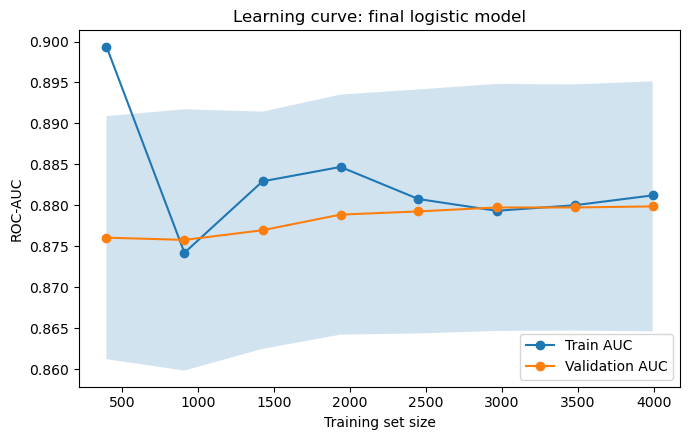

Final point -> train 0.881 | validation 0.880 | gap 0.001


In [27]:
import joblib
from sklearn.model_selection import learning_curve

# ---- 1. Four tiers using OOF-based cut-offs ----
t_watch = 0.33
cutoffs = {"High": t_high, "Medium": t_med, "Watch": t_watch}

def assign_tier(score, cuts):
    return np.where(score >= cuts["High"], "High",
           np.where(score >= cuts["Medium"], "Medium",
           np.where(score >= cuts["Watch"], "Watch", "Low")))

tier = assign_tier(test_scores, cutoffs)
rep = (pd.DataFrame({"tier": tier, "pip": y_test.values})
       .groupby("tier")["pip"].agg(employees="count", pip_cases="sum")
       .loc[["High", "Medium", "Watch", "Low"]])
rep["pip_rate_%"] = (rep["pip_cases"] / rep["employees"] * 100).round(1)
rep["cum_employees_%"] = (rep["employees"].cumsum() / len(y_test) * 100).round(1)
rep["cum_recall_%"] = (rep["pip_cases"].cumsum() / y_test.sum() * 100).round(1)
display(rep)

# ---- 2. Learning curve (bias / variance) ----
sizes, tr_sc, va_sc = learning_curve(
    final, X_train[keep], y_train, cv=skf, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
plt.figure(figsize=(7, 4.5))
plt.plot(sizes, tr_sc.mean(axis=1), "o-", label="Train AUC")
plt.plot(sizes, va_sc.mean(axis=1), "o-", label="Validation AUC")
plt.fill_between(sizes, va_sc.mean(axis=1) - va_sc.std(axis=1),
                 va_sc.mean(axis=1) + va_sc.std(axis=1), alpha=0.2)
plt.xlabel("Training set size")
plt.ylabel("ROC-AUC")
plt.title("Learning curve: final logistic model")
plt.legend()
plt.tight_layout()
plt.show()
print("Final point -> train {:.3f} | validation {:.3f} | gap {:.3f}".format(
    tr_sc.mean(axis=1)[-1], va_sc.mean(axis=1)[-1],
    tr_sc.mean(axis=1)[-1] - va_sc.mean(axis=1)[-1]))



**Inference (four tiers (test set, 1,248 employees, 251 PIP cases))**
- **High:** 196 employees, 134 PIP cases, **68.4%** rate. **Medium:** 265, 77 cases, 29.1%. **Watch:** 110, 16 cases, 14.5%. **Low:** 677, 24 cases, 3.5%.
- Review **High + Medium** (37% of employees) and you catch **84%** of PIP cases. Add **Watch** (46% of employees) and you catch **90%**. The Low tier (54% of employees) holds only about 10% of PIP cases.
- Note that the Watch tier's rate (14.5%) is below the company average (20.1%). It is included only to raise recall, and its risk is still about 4 times that of the Low tier.
- **Learning curve:** train AUC 0.881 and validation AUC 0.880, a gap of **0.001**. There is no overfitting, and the validation curve is flat, so more data of the same kind will not help. New information would (for example peer feedback or earlier PIP history).



## Part 16: Reliability and fairness checks
Is the result stable, and does the model work for every group?

In [28]:
# ---- 1. Bootstrap: how much would our test numbers move by chance? ----
rng = np.random.default_rng(42)
yt, st = y_test.values, test_scores
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    yb, sb = yt[idx], st[idx]
    boot.append({
        "auc": roc_auc_score(yb, sb),
        "recall @Medium cut": recall_score(yb, (sb >= t_med).astype(int)),
        "recall @Watch cut": recall_score(yb, (sb >= t_watch).astype(int)),
        "precision @High cut": precision_score(yb, (sb >= t_high).astype(int),
                                               zero_division=0),
    })
ci = pd.DataFrame(boot).quantile([0.025, 0.5, 0.975]).T.round(3)
ci.columns = ["low_2.5%", "median", "high_97.5%"]
display(ci)

# ---- 2. Subgroup check at the Watch cut-off (recall / precision per group) ----
grp = X_test[["department", "employment_type", "job_level"]].copy()
grp["gender"] = df_clean.loc[X_test.index, "gender"]   # not a model feature
grp["y"] = y_test.values
grp["flag"] = (test_scores >= t_watch).astype(int)

for col in ["department", "employment_type", "job_level", "gender"]:
    rows = []
    for name, d in grp.groupby(col):
        rows.append({
            col: name,
            "n": len(d),
            "pip_rate": d["y"].mean(),
            "flagged_%": d["flag"].mean() * 100,
            "recall": d.loc[d["y"] == 1, "flag"].mean(),
            "precision": d.loc[d["flag"] == 1, "y"].mean(),
        })
    print(f"\n--- By {col} ---")
    display(pd.DataFrame(rows).set_index(col).round(3))

,low_2.5%,median,high_97.5%
auc,0.858,0.882,0.905
recall @Medium cut,0.795,0.843,0.887
recall @Watch cut,0.869,0.906,0.941
precision @High cut,0.612,0.683,0.745



--- By department ---


,n,pip_rate,flagged_%,recall,precision
department,,,,,
Customer Support,198,0.212,52.525,0.929,0.375
Engineering,310,0.145,35.806,0.733,0.297
Finance,115,0.235,42.609,0.889,0.490
HR,61,0.262,52.459,0.938,0.469
IT,64,0.141,43.750,0.778,0.250
Marketing,100,0.200,44.000,1.000,0.455
Operations,186,0.247,50.538,0.978,0.479
Sales,214,0.215,50.935,0.957,0.404



--- By employment_type ---


,n,pip_rate,flagged_%,recall,precision
employment_type,,,,,
Contract,167,0.234,49.102,0.846,0.402
Full-time,1081,0.196,45.236,0.915,0.397



--- By job_level ---


,n,pip_rate,flagged_%,recall,precision
job_level,,,,,
1,202,0.282,52.475,0.947,0.509
2,430,0.223,50.698,0.927,0.408
3,374,0.168,42.781,0.889,0.350
4,190,0.153,37.368,0.862,0.352
5,52,0.115,30.769,0.500,0.188



--- By gender ---


,n,pip_rate,flagged_%,recall,precision
gender,,,,,
Female,531,0.203,46.704,0.898,0.391
Male,707,0.199,45.262,0.908,0.400
Other,10,0.200,30.000,1.000,0.667


**Inference (bootstrap ranges and groups on the test set)**
- The test set has only 251 PIP cases, so we resampled it 1,000 times. Real-world ranges: **AUC 0.858-0.905**, recall at the Watch cut-off 0.869-0.941, precision in the High tier 0.612-0.745.
- **Gender** (not a model input): recall is 0.898 for Female and 0.908 for Male, and the share flagged is 46.7% and 45.3%. No gender gap was found. The "Other" group has only 10 employees, too few to judge.
- Engineering looks weak here (recall 0.733) but it has only about 45 PIP cases, so we re-check it on more data next.

In [29]:
# ---- 1. Recall by group using TRAIN out-of-fold scores (bigger sample) ----
g = X_train[["department", "employment_type", "job_level"]].copy()
g["y"] = y_train.values
g["flag"] = (oof >= t_watch).astype(int)

for col in ["department", "employment_type", "job_level"]:
    rows = []
    for name, d in g.groupby(col):
        pos = d[d["y"] == 1]
        rows.append({
            col: name,
            "n": len(d),
            "pip_cases": len(pos),
            "pip_rate": d["y"].mean(),
            "recall": pos["flag"].mean(),
            "precision": d.loc[d["flag"] == 1, "y"].mean(),
        })
    print(f"\n--- OOF by {col} ---")
    display(pd.DataFrame(rows).set_index(col).round(3))

# ---- 2. Engineering: what do the MISSED PIP cases look like? ----
eng = X_train[X_train["department"] == "Engineering"].copy()
eng["y"] = y_train.loc[eng.index].values
eng["flag"] = (oof[X_train.index.get_indexer(eng.index)] >= t_watch).astype(int)

eng_pip = eng[eng["y"] == 1]
cmp_cols = ["kpi_score", "quality_score", "manager_rating",
            "goal_completion_rate", "attendance_risk_index",
            "rework_count_last_month", "client_escalations_count_3m",
            "policy_violation_count_6m", "overdue_task_ratio", "job_level"]
profile = eng_pip.groupby("flag")[cmp_cols].mean().T
profile.columns = ["missed (flag=0)", "caught (flag=1)"]
print("\nEngineering PIP cases: missed =", int((eng_pip['flag'] == 0).sum()),
      "| caught =", int((eng_pip['flag'] == 1).sum()))
display(profile.round(2))


--- OOF by department ---


,n,pip_cases,pip_rate,recall,precision
department,,,,,
Customer Support,821,219,0.267,0.941,0.438
Engineering,1115,169,0.152,0.852,0.363
Finance,483,89,0.184,0.876,0.364
HR,316,57,0.180,0.860,0.377
IT,282,53,0.188,0.962,0.451
Marketing,393,66,0.168,0.848,0.346
Operations,678,159,0.235,0.918,0.412
Sales,904,192,0.212,0.922,0.402



--- OOF by employment_type ---


,n,pip_cases,pip_rate,recall,precision
employment_type,,,,,
Contract,630,151,0.240,0.934,0.416
Full-time,4362,853,0.196,0.898,0.395



--- OOF by job_level ---


,n,pip_cases,pip_rate,recall,precision
job_level,,,,,
1,806,201,0.249,0.900,0.384
2,1649,375,0.227,0.917,0.418
3,1565,295,0.188,0.915,0.415
4,828,114,0.138,0.851,0.333
5,144,19,0.132,0.789,0.333



Engineering PIP cases: missed = 25 | caught = 144


,missed (flag=0),caught (flag=1)
kpi_score,70.67,53.32
quality_score,70.35,56.85
manager_rating,3.56,2.40
goal_completion_rate,0.72,0.57
attendance_risk_index,9.00,15.30
rework_count_last_month,1.32,2.74
client_escalations_count_3m,0.20,1.01
policy_violation_count_6m,0.40,0.65
overdue_task_ratio,0.09,0.11
job_level,3.44,3.08


**Inference (groups on the larger training sample (out-of-fold))**
- With 169 Engineering PIP cases the recall is **0.852**, close to the overall recall of about 0.90. The low test figure was small-sample noise. All departments fall between 0.85 and 0.96.
- Engineering has the lowest PIP rate (15.2%), and one shared cut-off gives slightly lower recall in low-rate groups, so no separate model is needed.
- The 25 missed Engineering PIP cases look **healthy on paper**: KPI 70.7 (caught cases 53.3), manager rating 3.56 (caught 2.40), client escalations 0.20 (caught 1.01). The reason for their PIP is not in these columns.
- Groups with few PIP cases (IT, job level 5) are too small to draw conclusions from.

---
## Part 17: Label audit: where is the model wrong?
We look at confident mistakes to see whether the model or the labels are the limit.

In [30]:
# ---- 1. Build an audit table from out-of-fold TRAIN scores ----
aud = X_train[keep].copy()
aud["y"] = y_train.values
aud["score"] = oof

# ---- 2. PIP rate by score decile (does the ranking separate well?) ----
aud["decile"] = pd.qcut(aud["score"].rank(method="first"), 10,
                        labels=range(1, 11))
dec = aud.groupby("decile", observed=True)["y"].agg(
    employees="count", pip_cases="sum", pip_rate="mean")
dec["pip_rate"] = (dec["pip_rate"] * 100).round(1)
print("--- PIP rate by score decile (10 = highest risk) ---")
display(dec)

# ---- 3. Four groups to compare ----
groups = {
    "confident false alarm": aud[(aud.y == 0) & (aud.score >= t_high)],
    "true PIP (High tier)":  aud[(aud.y == 1) & (aud.score >= t_high)],
    "missed PIP (Low tier)": aud[(aud.y == 1) & (aud.score < t_watch)],
    "true non-PIP (Low)":    aud[(aud.y == 0) & (aud.score < t_watch)],
}
print("\n--- Group sizes ---")
for name, g_ in groups.items():
    print(f"{name:<24}: {len(g_)}")

# ---- 4. Average profile of each group ----
profile = pd.DataFrame({name: g_[keep].mean() for name, g_ in groups.items()})
print("\n--- Average feature values per group ---")
display(profile.round(2))

--- PIP rate by score decile (10 = highest risk) ---


,employees,pip_cases,pip_rate
decile,,,
1,500,1,0.2
2,499,5,1.0
3,499,12,2.4
4,499,25,5.0
5,499,35,7.0
6,499,59,11.8
7,499,90,18.0
8,499,152,30.5
9,499,237,47.5



--- Group sizes ---
confident false alarm   : 299
true PIP (High tier)    : 567
missed PIP (Low tier)   : 97
true non-PIP (Low)      : 2615

--- Average feature values per group ---


,confident false alarm,true PIP (High tier),missed PIP (Low tier),true non-PIP (Low)
kpi_score,52.89,48.72,70.16,75.83
quality_score,57.40,53.57,70.88,77.17
goal_completion_rate,0.55,0.52,0.73,0.78
training_hours_last_3m,17.45,16.53,19.22,18.62
manager_rating,2.33,2.11,3.61,3.98
client_escalations_count_3m,1.28,1.58,0.57,0.43
policy_violation_count_6m,0.62,0.64,0.37,0.31
job_level,2.29,2.31,2.53,2.73
rework_count_last_month,2.40,2.88,1.45,1.17
overdue_task_ratio,0.12,0.12,0.09,0.08


**Inference (deciles and confident mistakes)**
- PIP rate climbs steadily from 0.2% in the lowest-score decile to **77.6%** in the highest. The top 20% of employees hold 625 of 1,004 PIP cases (62%), and the bottom 50% hold only 78 (7.8%).
- The 299 **confident false alarms** look like true PIP cases (KPI 52.9 vs 48.7, manager rating 2.33 vs 2.11) and nothing like true non-PIP employees (KPI 75.8, rating 3.98). They are struggling employees who **did not receive a PIP**.
- The 97 **missed PIP cases** look healthy (KPI 70.2, rating 3.61). Their PIP reason is outside the data.
- many "false alarms" are not really wrong. They are employees HR may want to support, and the limit is the label (a manager's decision), not the model.


## Part 18: Calibration: make scores mean real risk
Class weights inflate the scores. A small calibration step turns them into honest probabilities. Ranking, recall and tiers stay unchanged.

In [31]:
from scipy.special import logit
from sklearn.metrics import brier_score_loss

# ---- 1. Fit a 1-D Platt calibrator on TRAIN out-of-fold scores ----
eps = 1e-6
z_oof = logit(np.clip(oof, eps, 1 - eps)).reshape(-1, 1)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(z_oof, y_train)

# ---- 2. Apply to TEST scores ----
z_test = logit(np.clip(test_scores, eps, 1 - eps)).reshape(-1, 1)
cal_test = platt.predict_proba(z_test)[:, 1]

print("Brier score (lower is better)  raw: {:.4f} | calibrated: {:.4f}".format(
    brier_score_loss(y_test, test_scores), brier_score_loss(y_test, cal_test)))
print("AUC  raw: {:.4f} | calibrated: {:.4f}  (should be the same)".format(
    roc_auc_score(y_test, test_scores), roc_auc_score(y_test, cal_test)))

# ---- 3. Reliability table by test decile: predicted vs actual ----
t_df = pd.DataFrame({"raw": test_scores, "cal": cal_test, "y": y_test.values})
t_df["decile"] = pd.qcut(t_df["raw"].rank(method="first"), 10,
                         labels=range(1, 11))
rel = t_df.groupby("decile", observed=True).agg(
    employees=("y", "count"),
    avg_raw_score=("raw", "mean"),
    avg_calibrated_risk=("cal", "mean"),
    actual_pip_rate=("y", "mean")).round(3)
display(rel)

# ---- 4. What do the tier cut-offs mean as real risk %? ----
print("\nTier cut-offs as calibrated risk:")
for name, c_ in cutoffs.items():
    p = platt.predict_proba(
        logit(np.clip(np.array([[c_]]), eps, 1 - eps)))[0, 1]
    print(f"  {name:<7} raw score {c_:.2f}  ->  about {p*100:.0f}% PIP risk")

Brier score (lower is better)  raw: 0.1370 | calibrated: 0.0999
AUC  raw: 0.8811 | calibrated: 0.8811  (should be the same)


,employees,avg_raw_score,avg_calibrated_risk,actual_pip_rate
decile,,,,
1,125,0.016,0.004,0.000
2,125,0.051,0.014,0.008
3,125,0.095,0.026,0.048
4,124,0.157,0.045,0.032
5,125,0.239,0.074,0.072
6,125,0.335,0.114,0.120
7,124,0.450,0.172,0.169
8,125,0.596,0.273,0.328
9,125,0.764,0.452,0.424



Tier cut-offs as calibrated risk:
  High    raw score 0.75  ->  about 43% PIP risk
  Medium  raw score 0.42  ->  about 15% PIP risk
  Watch   raw score 0.33  ->  about 11% PIP risk


**Inference (calibration)**
- Brier score improves from 0.137 to **0.0999** (lower is better), and AUC stays **0.8811**, so only the meaning of the scores changed.
- Raw scores overstate risk (decile 5: raw 0.24 against an actual 7%). Calibrated risk is close to reality: decile 10 predicts 76% against an actual 81%, decile 9 predicts 45% against 42%, decile 7 predicts 17% against 17%.
- As a risk %, the cut-offs are High about 43%, Medium about 15% and Watch about 11%. This is the risk of the **last person admitted** to each tier. The tier averages are higher (68%, 29%, 14.5%).


## Summary and how to use the model

| Item | Result |
|---|---|
| Final model | Weighted logistic regression, 12 features, C = 0.1 |
| Ranking quality (test) | ROC-AUC **0.881** (95% range 0.858-0.905) |
| Overfitting | None: train 0.881 vs validation 0.880 |
| Review High + Medium (37% of employees) | catches about **84%** of PIP cases |
| Review High + Medium + Watch (46%) | catches about **90%** of PIP cases |
| Top driver of lower risk | KPI and quality score |
| Top driver of higher risk | Attendance risk index |

**How HR should use it**
- A tier is a **signal to talk to the manager**, not a decision to start a PIP. About 1 in 3 High-tier employees did not receive a PIP, and many of them look like struggling employees who may need support.
- Choose how deep to go (High only, +Medium, +Watch) from the review capacity. Beyond 90% recall each extra case costs twice as many reviews.

**Limitations**
- The label comes from past manager decisions, so the model can repeat their habits.
- About 10% of PIP cases are missed even at 90% recall. They look healthy in the data.
- Odds ratios show association, not cause. Group results for IT and job level 5 are too small to judge.
- Data source and time period are not documented, so we could not test on a later period.

**What would improve it:** new information, such as trends over time (KPI last month vs now), peer feedback, earlier PIP history and manager ID. Trying more algorithms did not help.